****RESHAPE THE DATA TO SUIT THE ANALYSIS****

In [3]:
import pandas as pd
from pathlib import Path

# ==============================================================
# USER INPUTS
# ==============================================================

# Paths to your Excel files
precip_path = Path("precipitation_data.xlsx")   # workbook with 8 sheets
temp_path = Path("temperature_data.xlsx")       # workbook with 8 sheets

# Output file name
output_file = Path("reshaped_climate_data.xlsx")

# ==============================================================
# FUNCTION TO RESHAPE DATA FROM MULTIPLE SHEETS
# ==============================================================

def reshape_climate_data(file_path, parameter_name):
    """
    Reads an Excel workbook (one sheet per location),
    reshapes all sheets into a long-format DataFrame with columns:
    ['Date', 'Year', 'Month', 'Location', parameter_name]
    """
    all_dfs = []
    
    # Read all sheet names
    sheet_names = pd.ExcelFile(file_path).sheet_names
    
    for sheet in sheet_names:
        df = pd.read_excel(file_path, sheet_name=sheet)
        df = df.melt(id_vars=["YEAR"], 
                     var_name="Month", 
                     value_name=parameter_name)
        df["Location"] = sheet  # add location from sheet name
        
        # Convert month abbreviations to numbers
        df["Month"] = pd.to_datetime(df["Month"], format="%b").dt.month
        
        # Create Date column (set to 15th day of each month)
        df["Date"] = pd.to_datetime(dict(year=df["YEAR"], month=df["Month"], day=15))
        
        # Reorder columns
        df = df[["Date", "YEAR", "Month", "Location", parameter_name]]
        
        all_dfs.append(df)
    
    # Combine all locations into one DataFrame
    full_df = pd.concat(all_dfs, ignore_index=True)
    return full_df


# ==============================================================
# PROCESS PRECIPITATION AND TEMPERATURE
# ==============================================================

precip_long = reshape_climate_data(precip_path, "Precipitation")
temp_long = reshape_climate_data(temp_path, "Temperature")

# ==============================================================
# CREATE WIDE FORMAT (for SPI/SPEI computation)
# ==============================================================

# Pivot so each location becomes a column
precip_wide = precip_long.pivot_table(index="Date", 
                                      columns="Location", 
                                      values="Precipitation").sort_index()

temp_wide = temp_long.pivot_table(index="Date", 
                                  columns="Location", 
                                  values="Temperature").sort_index()

# ==============================================================
# SAVE TO EXCEL (each dataset in a separate sheet)
# ==============================================================

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    precip_long.to_excel(writer, sheet_name="Precip_Long", index=False)
    temp_long.to_excel(writer, sheet_name="Temp_Long", index=False)
    precip_wide.to_excel(writer, sheet_name="Precip_Wide")
    temp_wide.to_excel(writer, sheet_name="Temp_Wide")

print(f"✅ All data reshaped and saved to: {output_file.resolve()}")

✅ All data reshaped and saved to: /Users/apple/Desktop/Python/AC-ITA/reshaped_climate_data.xlsx


**Potential Evapotranspiration (PET) Analysis**

In [5]:
import pandas as pd
import numpy as np
from math import sin, radians, acos, tan, pi
from pathlib import Path

# -----------------------------
# User-editable latitude table
# Keys should be the "clean" form of your sheet/column names (see cleaning function)
# -----------------------------
latitudes = {
    "yenagoa": 4.95,
    "ikot akpaden": 4.62,
    "ibadan": 7.38,
    "abuja": 9.07,
    "jalingo": 8.89,
    "sokoto": 13.01,
    "gombe": 10.28,
    "kukawa": 12.92
}

# -----------------------------
# Helpers
# -----------------------------
def clean_name(name):
    """Normalize column/sheet names for matching with latitude dict."""
    if not isinstance(name, str):
        return str(name).strip().lower()
    s = name.strip().lower()
    s = s.replace("_", " ")
    s = " ".join(s.split())  # collapse multiple spaces
    return s

def day_of_year_for_month(m):
    """Return a representative day-of-year for a month (middle of month)."""
    # approximate middle day for each month (non-leap-year)
    mid_days = [15, 46, 75, 105, 135, 166, 196, 227, 258, 288, 319, 349]
    return mid_days[m-1]

def month_declination_rad(month):
    """Solar declination (radians) approximate for month-middle day."""
    day = day_of_year_for_month(month)
    # declination in degrees
    decl_deg = 23.45 * sin(radians(360 * (284 + day) / 365.0))
    return radians(decl_deg)

def day_length_hours(lat_rad, decl_rad):
    """Compute daylength hours for given latitude and solar declination."""
    # handle edge cases for tan(lat)*tan(decl) out of [-1,1]
    x = -tan(lat_rad) * tan(decl_rad)
    # clip x to [-0.9999, 0.9999] to avoid domain error
    x = max(min(x, 0.999999), -0.999999)
    ws = acos(x)  # hour angle in radians
    day_hours = 24.0 / pi * ws
    return day_hours

def thornthwaite_pet_series(temp_series, lat_deg):
    """
    Compute Thornthwaite PET (mm/month) for a pandas Series of monthly mean temp.
    temp_series: pandas Series indexed by datetime (monthly frequency)
    lat_deg: latitude in decimal degrees
    Returns: pandas Series (same index) with PET in mm/month
    """
    # Ensure datetime index
    if not isinstance(temp_series.index, pd.DatetimeIndex):
        raise ValueError("temp_series must have a DatetimeIndex with monthly dates.")
    # Sort
    ts = temp_series.sort_index()
    # Replace missing temps with NaN but keep index
    temps = ts.astype(float)

    # Compute monthly climatology (month-of-year means) ignoring NaNs
    monthly_clim = temps.groupby(temps.index.month).mean()
    # Guarantee 1..12 index
    monthly_clim = monthly_clim.reindex(range(1,13), fill_value=np.nan)

    # Replace NaNs in monthly_clim with zeros for I computation (assumes missing months rare)
    monthly_clim_for_I = monthly_clim.fillna(0.0)

    # Annual heat index I
    I = ((monthly_clim_for_I / 5.0) ** 1.514).sum()
    if I <= 0:
        # fallback: if I zero (all temps <= 0), return zeros
        return pd.Series(0.0, index=temps.index)

    # Exponent a
    a = (6.75e-7)*(I**3) - (7.71e-5)*(I**2) + (1.792e-2)*I + 0.49239

    # Precompute daylength correction per month
    lat_rad = radians(lat_deg)
    daylength_factors = {}
    for m in range(1,13):
        decl = month_declination_rad(m)
        dh = day_length_hours(lat_rad, decl)
        L = dh / 12.0  # normalize to 12h baseline
        # N/30 factor used sometimes: we'll multiply final PET by (N/30) ~ (dh/12)
        daylength_factors[m] = L

    # Compute PET for each timestamp using its month-of-year and its temp
    pet_vals = []
    for idx, T in temps.items():
        m = idx.month
        Tpos = T if (not np.isnan(T) and T > 0) else np.nan
        if np.isnan(Tpos):
            pet_vals.append(np.nan)
        else:
            L = daylength_factors[m]
            pet_m = 16.0 * ((10.0 * Tpos / I) ** a) * L
            pet_vals.append(pet_m)

    pet_series = pd.Series(pet_vals, index=temps.index)
    return pet_series

# -----------------------------
# Main: read file, compute PET, save sheet
# -----------------------------
file_path = Path("reshaped_climate_data.xlsx")
sheet_in = "Temp_Wide"
sheet_out = "PET_Wide"

# Read temperature wide sheet
df = pd.read_excel(file_path, sheet_name=sheet_in)

# Normalize column names for internal mapping but keep originals for output
orig_cols = df.columns.tolist()
clean_col_map = {c: clean_name(c) for c in orig_cols}

# Ensure Date exists or create it
if "Date" not in df.columns:
    if "Year" in df.columns and "Month" in df.columns:
        # month might be numeric or string; try to parse to month number
        try:
            # if Month is like 1..12 it's fine
            if df["Month"].dtype == object:
                # attempt parse Jan/Feb etc
                df["Month_num"] = pd.to_datetime(df["Month"], format="%b", errors="coerce").dt.month
                if df["Month_num"].isna().all():
                    df["Month_num"] = pd.to_datetime(df["Month"], format="%B", errors="coerce").dt.month
                # fallback numeric convert
                df["Month_num"] = df["Month_num"].fillna(pd.to_numeric(df["Month"], errors="coerce"))
            else:
                df["Month_num"] = df["Month"].astype(int)
        except Exception:
            df["Month_num"] = pd.to_numeric(df["Month"], errors="coerce")
        df["Date"] = pd.to_datetime(dict(year=df["Year"], month=df["Month_num"], day=15), errors="coerce")
        df.drop(columns=["Month_num"], inplace=True)
    else:
        raise SystemExit("Temp_Wide must contain 'Date' or both 'Year' and 'Month' columns.")

# Set Date as index for time-series ops
df = df.sort_values("Date").reset_index(drop=True)
df = df.set_index(pd.DatetimeIndex(df["Date"]))

# Prepare output PET dataframe with Year/Month/Date columns
pet_df = df[["Year","Month","Date"]].copy().reset_index(drop=True)

# Identify location columns: those not Year/Month/Date
loc_cols = [c for c in df.columns if c not in ["Year","Month","Date"]]
print("Detected location columns:", loc_cols)

# For each location, try to find matching latitude by cleaned name
matched = {}
for col in loc_cols:
    cname = clean_name(col)
    if cname in latitudes:
        matched[col] = latitudes[cname]
    else:
        # try more flexible matching: match ignoring spaces/punctuation
        for lk in latitudes.keys():
            if lk.replace(" ", "") == cname.replace(" ", ""):
                matched[col] = latitudes[lk]
                break

print("Matched locations -> latitudes:", matched)

# Compute PET for matched locations; warn for unmatched
for col in loc_cols:
    if col not in matched:
        print(f"⚠️ No latitude found for column '{col}'. Skipping PET for this column.")
        pet_df[col] = np.nan
        continue
    lat = matched[col]
    # Build series of temps for this location (indexed by Date)
    temp_series = df[col].astype(float)
    # Compute PET series
    pet_series = thornthwaite_pet_series(temp_series, lat)
    pet_df[col] = pet_series.values

# Reorder columns: Year, Month, Date, then locations (original order)
cols_out = ["Year","Month","Date"] + loc_cols
pet_df = pet_df[cols_out]

# Save to Excel (replace sheet if exists)
with pd.ExcelWriter(file_path, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    pet_df.to_excel(writer, sheet_name=sheet_out, index=False)

print(f"\n✅ PET_Wide saved to '{sheet_out}' in {file_path.name}")
print(pet_df.head())

Detected location columns: ['ABUJA', 'GOMBE', 'IBADAN', 'IKOT AKPADEN', 'JALINGO', 'KUKAWA', 'SOKOTO', 'YENAGOA']
Matched locations -> latitudes: {'ABUJA': 9.07, 'GOMBE': 10.28, 'IBADAN': 7.38, 'IKOT AKPADEN': 4.62, 'JALINGO': 8.89, 'KUKAWA': 12.92, 'SOKOTO': 13.01, 'YENAGOA': 4.95}

✅ PET_Wide saved to 'PET_Wide' in reshaped_climate_data.xlsx
   Year  Month       Date       ABUJA       GOMBE      IBADAN  IKOT AKPADEN  \
0  1981      1 1981-01-15   62.452326   83.340077   97.149052    137.569085   
1  1981      2 1981-02-15   93.865559  150.364784  119.492877    173.811789   
2  1981      3 1981-03-15  142.930111  280.551192  130.379941    180.248332   
3  1981      4 1981-04-15  145.608136  297.666289  135.473942    184.201590   
4  1981      5 1981-05-15  117.137509  244.944707  122.419362    155.418373   

      JALINGO      KUKAWA      SOKOTO     YENAGOA  
0   65.553621   42.379132   53.396406  107.449808  
1  122.311080  117.664533  115.616819  133.006884  
2  219.028587  355.4384

**SPEI AND SPI ANALYSIS**

In [6]:
# Requirements:
# pip install pandas numpy scipy openpyxl

import pandas as pd
import numpy as np
from scipy import stats
from pathlib import Path

# ---------------------------
# User inputs
# ---------------------------
file_path = Path("reshaped_climate_data.xlsx")
precip_sheet = "Precip_Wide"
pet_sheet = "PET_Wide"
output_file = file_path  # write back to same workbook (replacing sheets if present)

timescales = [1, 3, 6, 12]  # months to compute SPI/SPEI for

# ---------------------------
# Utility functions
# ---------------------------
def fit_gamma_cdf(values):
    """Fit gamma(a, loc=0, scale) to positive values and return fitted parameters."""
    # values: 1D numpy array of positive values (>0)
    # Use floc=0 to force loc=0 (standard for SPI)
    a, loc, scale = stats.gamma.fit(values, floc=0)
    return a, loc, scale

def safe_ppf(cdf_vals):
    """Convert CDF to standard normal z (ppf). Clip extreme probabilities to avoid inf."""
    eps = 1e-10
    cdf_vals = np.clip(cdf_vals, eps, 1 - eps)
    return stats.norm.ppf(cdf_vals)

def compute_spi_for_series(precip_series, scale):
    """
    precip_series: pandas Series indexed by datetime (mm)
    scale: int months
    returns: pandas Series of SPI (aligned to end of rolling window)
    """
    # rolling aggregate (sum)
    p_agg = precip_series.rolling(window=scale, min_periods=scale).sum().dropna()

    # probability of zeros in aggregated series
    p0 = (p_agg == 0).sum() / len(p_agg) if len(p_agg) > 0 else 0.0

    # prepare non-zero values for gamma fit
    nonzero = p_agg[p_agg > 0].values
    if len(nonzero) < 10:
        # Too few non-zero points to fit reliably; return NaNs
        return pd.Series(np.nan, index=p_agg.index)

    a, loc, scale_g = fit_gamma_cdf(nonzero)

    # compute CDF for all aggregated values
    cdf_all = []
    for v in p_agg.values:
        if v <= 0:
            cdf = p0
        else:
            # gamma.cdf handles positive v
            cdf = p0 + (1 - p0) * stats.gamma.cdf(v, a, loc=loc, scale=scale_g)
        cdf_all.append(cdf)

    cdf_all = np.array(cdf_all)
    spi_vals = safe_ppf(cdf_all)
    spi = pd.Series(spi_vals, index=p_agg.index)
    return spi

def compute_spei_for_series(precip_series, pet_series, scale):
    """
    Compute SPEI for one location (P and PET series).
    D = P - PET, rolling sum of D, fit log-logistic (Fisk) after shifting positive.
    """
    D = precip_series - pet_series
    D_agg = D.rolling(window=scale, min_periods=scale).sum().dropna()
    if len(D_agg) < 10:
        return pd.Series(np.nan, index=D_agg.index)

    # shift so all values positive (needed for fitting Fisk). add small epsilon
    minD = D_agg.min()
    shift = 0.0
    if minD <= 0:
        shift = abs(minD) + 1e-6
    D_shift = D_agg + shift

    # Fit Fisk (log-logistic) distribution
    try:
        c, loc, scale_f = stats.fisk.fit(D_shift, floc=0)
    except Exception:
        c, loc, scale_f = stats.fisk.fit(D_shift)

    cdf_vals = stats.fisk.cdf(D_shift.values, c, loc=loc, scale=scale_f)
    spei_vals = safe_ppf(cdf_vals)
    spei = pd.Series(spei_vals, index=D_agg.index)
    return spei

# ---------------------------
# Load data
# ---------------------------
precip_df = pd.read_excel(file_path, sheet_name=precip_sheet)
pet_df = pd.read_excel(file_path, sheet_name=pet_sheet)

# Convert Date column to datetime and set index
if "Date" in precip_df.columns:
    precip_df["Date"] = pd.to_datetime(precip_df["Date"], errors="coerce")
else:
    # try Year/Month to build Date
    precip_df["Date"] = pd.to_datetime(dict(year=precip_df["Year"], month=precip_df["Month"], day=15), errors="coerce")

if "Date" in pet_df.columns:
    pet_df["Date"] = pd.to_datetime(pet_df["Date"], errors="coerce")
else:
    pet_df["Date"] = pd.to_datetime(dict(year=pet_df["Year"], month=pet_df["Month"], day=15), errors="coerce")

precip_df = precip_df.sort_values("Date").set_index("Date")
pet_df = pet_df.sort_values("Date").set_index("Date")

# Align indices (common date range)
common_index = precip_df.index.intersection(pet_df.index)
precip_df = precip_df.reindex(common_index)
pet_df = pet_df.reindex(common_index)

# Determine location columns as those not Year/Month (if present)
exclude = {"Year", "Month", "Date"}
loc_cols = [c for c in precip_df.columns if c not in exclude]
# Make sure PET has same columns
loc_cols = [c for c in loc_cols if c in pet_df.columns]

if not loc_cols:
    raise SystemExit("No matching location columns found between Precip_Wide and PET_Wide.")

print("Computing SPI/SPEI for locations:", loc_cols)

# ---------------------------
# Compute and store results
# ---------------------------
# We'll create dictionaries: spi_results[scale] = dataframe, spei_results[scale] = dataframe
spi_results = {}
spei_results = {}

for scale in timescales:
    spi_df = pd.DataFrame(index=common_index)
    spei_df = pd.DataFrame(index=common_index)

    for loc in loc_cols:
        p_series = precip_df[loc].astype(float)
        pet_series = pet_df[loc].astype(float)

        # SPI
        spi_series = compute_spi_for_series(p_series, scale)
        # reindex to full common_index (so NaNs before first computed window)
        spi_df[loc] = spi_series.reindex(common_index)

        # SPEI
        spei_series = compute_spei_for_series(p_series, pet_series, scale)
        spei_df[loc] = spei_series.reindex(common_index)

    spi_results[scale] = spi_df
    spei_results[scale] = spei_df
    print(f"Computed SPI & SPEI for scale = {scale} months")

# ---------------------------
# Save results to workbook: create a sheet for each index+scale
# e.g., SPI_1, SPI_3, ..., SPEI_1, SPEI_3, ...
# ---------------------------
with pd.ExcelWriter(output_file, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    for scale, df_spi in spi_results.items():
        df_out = df_spi.reset_index().rename(columns={"index":"Date"})
        df_out.to_excel(writer, sheet_name=f"SPI_{scale}", index=False)
    for scale, df_spei in spei_results.items():
        df_out = df_spei.reset_index().rename(columns={"index":"Date"})
        df_out.to_excel(writer, sheet_name=f"SPEI_{scale}", index=False)

print(f"✅ SPI and SPEI sheets written to {output_file.name}")

Computing SPI/SPEI for locations: ['ABUJA', 'GOMBE', 'IBADAN', 'IKOT AKPADEN', 'JALINGO', 'KUKAWA', 'SOKOTO', 'YENAGOA']
Computed SPI & SPEI for scale = 1 months
Computed SPI & SPEI for scale = 3 months
Computed SPI & SPEI for scale = 6 months
Computed SPI & SPEI for scale = 12 months
✅ SPI and SPEI sheets written to reshaped_climate_data.xlsx


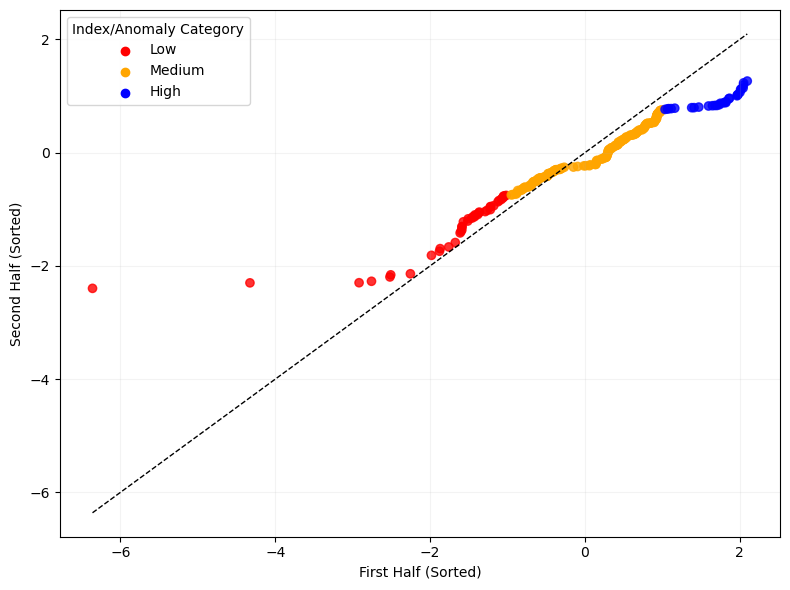

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------
# Load data
# --------------------------------------
df = pd.read_excel("reshaped_climate_data.xlsx", sheet_name="SPEI_12")
df["Date"] = pd.to_datetime(df["Date"])
df.set_index("Date", inplace=True)

location = "IKOT AKPADEN"   # change for other stations
series = df[location].dropna()

# --------------------------------------
# Assign SPEI categories BEFORE splitting
# --------------------------------------
def categorize(v):
    if v <= -1:
        return "Low"
    elif v >= 1:
        return "High"
    else:
        return "Medium"

categories = series.apply(categorize)

# --------------------------------------
# Split into two halves
# --------------------------------------
n = len(series)
mid = n // 2

x_vals = series.iloc[:mid].copy()
y_vals = series.iloc[mid:mid+mid].copy()

x_cat = categories.iloc[:mid].copy()
y_cat = categories.iloc[mid:mid+mid].copy()

# --------------------------------------
# Sort both halves independently
# Maintain the category labels!
# --------------------------------------
x_sorted_idx = np.argsort(x_vals)
y_sorted_idx = np.argsort(y_vals)

x_sorted = x_vals.iloc[x_sorted_idx].values
y_sorted = y_vals.iloc[y_sorted_idx].values

x_cat_sorted = x_cat.iloc[x_sorted_idx].values
y_cat_sorted = y_cat.iloc[y_sorted_idx].values

# --------------------------------------
# Choose the categories from X-axis for coloring
# --------------------------------------
colors = {"Low": "red", "Medium": "orange", "High": "blue"}
point_colors = [colors[c] for c in x_cat_sorted]

# --------------------------------------
# PLOT ITA WITH CATEGORY OVERLAY
# --------------------------------------
plt.figure(figsize=(8,6))

plt.scatter(x_sorted, y_sorted, c=point_colors, alpha=0.8)

# 1:1 line
maxv = max(max(x_sorted), max(y_sorted))
minv = min(min(x_sorted), min(y_sorted))
plt.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)


#plt.title(f"Sample plot for SH-ITA")
plt.xlabel("First Half (Sorted)")
plt.ylabel("Second Half (Sorted)")

# Legend
for lab, col in colors.items():
    plt.scatter([], [], color=col, label=lab)
plt.legend(title="Index/Anomaly Category")

plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

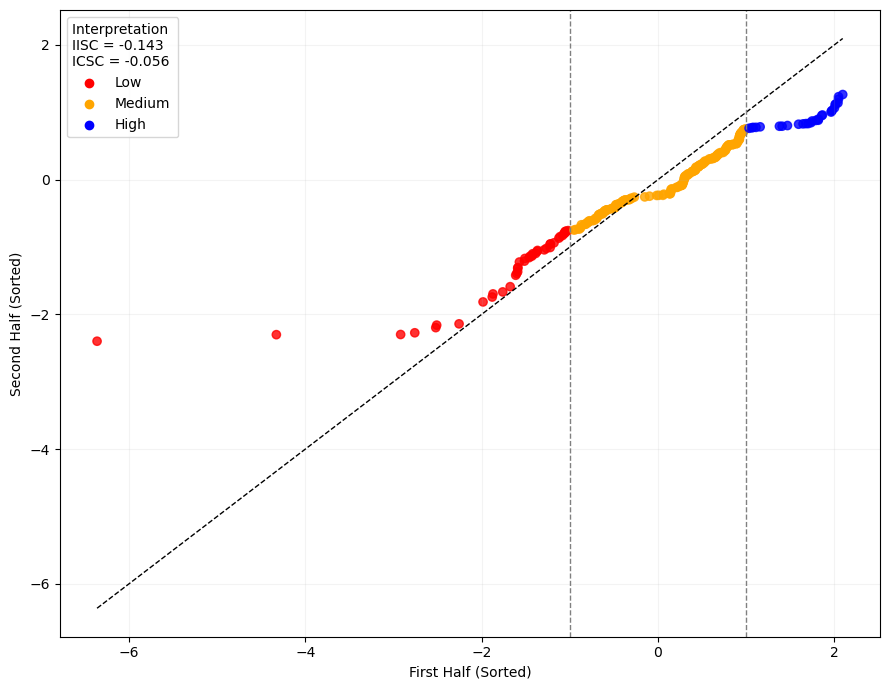

----------- SH-ITA Metrics -----------
Slope (Low)     = 0.4233
Slope (Medium)  = 0.7075
Slope (High)    = 0.3787
IISC            = -0.1434
ICSC            = -0.0556
--------------------------------------


In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# --------------------------------------
# Load data
# --------------------------------------
df = pd.read_excel("reshaped_climate_data.xlsx", sheet_name="SPEI_12")
df["Date"] = pd.to_datetime(df["Date"])
df.set_index("Date", inplace=True)

location = "IKOT AKPADEN"   # change for other stations
series = df[location].dropna()

# --------------------------------------
# Categorize SPEI BEFORE splitting
# --------------------------------------
def categorize(v):
    if v <= -1:
        return "Low"
    elif v >= 1:
        return "High"
    else:
        return "Medium"

categories = series.apply(categorize)

# --------------------------------------
# Split into two halves
# --------------------------------------
n = len(series)
mid = n // 2

x_vals = series.iloc[:mid].copy()
y_vals = series.iloc[mid:mid+mid].copy()

x_cat = categories.iloc[:mid].copy()
y_cat = categories.iloc[mid:mid+mid].copy()

# --------------------------------------
# Sort independently
# --------------------------------------
x_sorted_idx = np.argsort(x_vals)
y_sorted_idx = np.argsort(y_vals)

x_sorted = x_vals.iloc[x_sorted_idx].values
y_sorted = y_vals.iloc[y_sorted_idx].values

x_cat_sorted = x_cat.iloc[x_sorted_idx].values
y_cat_sorted = y_cat.iloc[y_sorted_idx].values

# --------------------------------------
# CATEGORY-SPECIFIC SLOPES
# --------------------------------------
def compute_slope(x, y, cat_labels, target_cat):
    subset = np.where(cat_labels == target_cat)[0]
    if len(subset) < 2:
        return np.nan  # not enough data
    X = x[subset].reshape(-1, 1)
    Y = y[subset]
    model = LinearRegression().fit(X, Y)
    return model.coef_[0]

slope_low = compute_slope(x_sorted, y_sorted, x_cat_sorted, "Low")
slope_med = compute_slope(x_sorted, y_sorted, x_cat_sorted, "Medium")
slope_high = compute_slope(x_sorted, y_sorted, x_cat_sorted, "High")

# --------------------------------------
# IISC CALCULATION
# --------------------------------------
X_mean = np.mean(x_sorted)
Y_mean = np.mean(y_sorted)
IISC = (Y_mean - X_mean) / np.mean(np.abs(x_sorted))

# --------------------------------------
# ICSC CALCULATION
# --------------------------------------
if np.isnan(slope_low) or np.isnan(slope_high):
    ICSC = np.nan
else:
    ICSC = (slope_high - slope_low) / np.abs(slope_high + slope_low)

# --------------------------------------
# Colors for points
# --------------------------------------
colors = {"Low": "red", "Medium": "orange", "High": "blue"}
point_colors = [colors[c] for c in x_cat_sorted]

# --------------------------------------
# PLOT SH-ITA
# --------------------------------------
plt.figure(figsize=(9,7))
plt.scatter(x_sorted, y_sorted, c=point_colors, alpha=0.8)

# 1:1 reference line
maxv = max(max(x_sorted), max(y_sorted))
minv = min(min(x_sorted), min(y_sorted))
plt.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

plt.xlabel("First Half (Sorted)")
plt.ylabel("Second Half (Sorted)")


# ------------------------------------------------
# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
# ------------------------------------------------
plt.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
plt.axvline(x=1, color="gray", linestyle="--", linewidth=1)


# --------------------------------------
# LEGEND with IISC & ICSC
# --------------------------------------
for lab, col in colors.items():
    plt.scatter([], [], color=col, label=f"{lab}")

plt.legend(
    title=f"Interpretation \nIISC = {IISC:.3f}\nICSC = {ICSC:.3f}",
    loc="upper left"
)

plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

# Print numeric results also
print("----------- SH-ITA Metrics -----------")
print(f"Slope (Low)     = {slope_low:.4f}")
print(f"Slope (Medium)  = {slope_med:.4f}")
print(f"Slope (High)    = {slope_high:.4f}")
print(f"IISC            = {IISC:.4f}")
print(f"ICSC            = {ICSC:.4f}")
print("--------------------------------------")

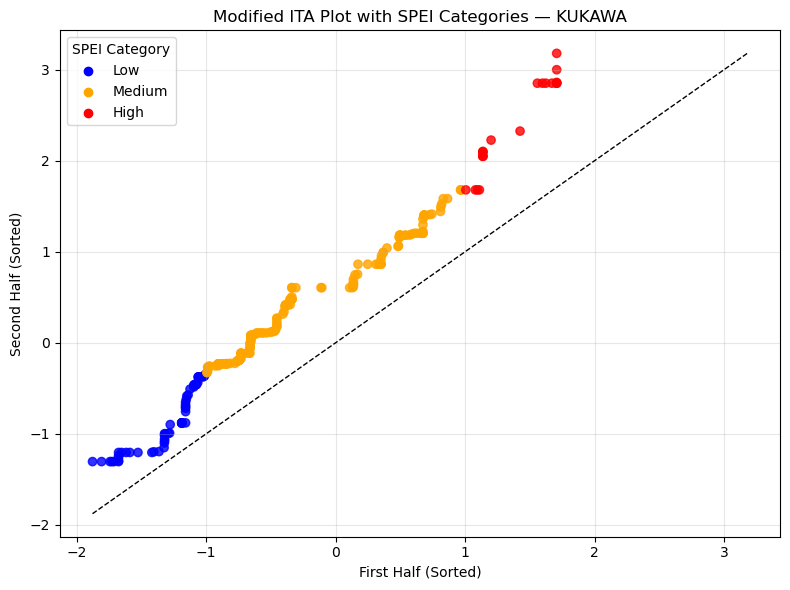

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------
# Load data
# --------------------------------------
df = pd.read_excel("reshaped_climate_data.xlsx", sheet_name="SPI_12")
df["Date"] = pd.to_datetime(df["Date"])
df.set_index("Date", inplace=True)

location = "KUKAWA"   # change for other stations
series = df[location].dropna()

# --------------------------------------
# Assign SPEI categories BEFORE splitting
# --------------------------------------
def categorize(v):
    if v <= -1:
        return "Low"
    elif v >= 1:
        return "High"
    else:
        return "Medium"

categories = series.apply(categorize)

# --------------------------------------
# Split into two halves
# --------------------------------------
n = len(series)
mid = n // 2

x_vals = series.iloc[:mid].copy()
y_vals = series.iloc[mid:mid+mid].copy()

x_cat = categories.iloc[:mid].copy()
y_cat = categories.iloc[mid:mid+mid].copy()

# --------------------------------------
# Sort both halves independently
# Maintain the category labels!
# --------------------------------------
x_sorted_idx = np.argsort(x_vals)
y_sorted_idx = np.argsort(y_vals)

x_sorted = x_vals.iloc[x_sorted_idx].values
y_sorted = y_vals.iloc[y_sorted_idx].values

x_cat_sorted = x_cat.iloc[x_sorted_idx].values
y_cat_sorted = y_cat.iloc[y_sorted_idx].values

# --------------------------------------
# Choose the categories from X-axis for coloring
# --------------------------------------
colors = {"Low": "blue", "Medium": "orange", "High": "red"}
point_colors = [colors[c] for c in x_cat_sorted]

# --------------------------------------
# PLOT ITA WITH CATEGORY OVERLAY
# --------------------------------------
plt.figure(figsize=(8,6))

plt.scatter(x_sorted, y_sorted, c=point_colors, alpha=0.8)

# 1:1 line
maxv = max(max(x_sorted), max(y_sorted))
minv = min(min(x_sorted), min(y_sorted))
plt.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

plt.title(f"Modified ITA Plot with SPEI Categories — {location}")
plt.xlabel("First Half (Sorted)")
plt.ylabel("Second Half (Sorted)")

# Legend
for lab, col in colors.items():
    plt.scatter([], [], color=col, label=lab)
plt.legend(title="SPEI Category")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

***SPI AND SPEI PLOTS***


=== CATEGORY SLOPES ===
Low Group Slope: 0.28938916563438594
Medium Group Slope: 1.0257450346081678
High Group Slope: 0.8619666883761886

Classical IISC: -0.26765717248267856
IISC-C (Category-Based Sensitivity): 0.49730717114723055


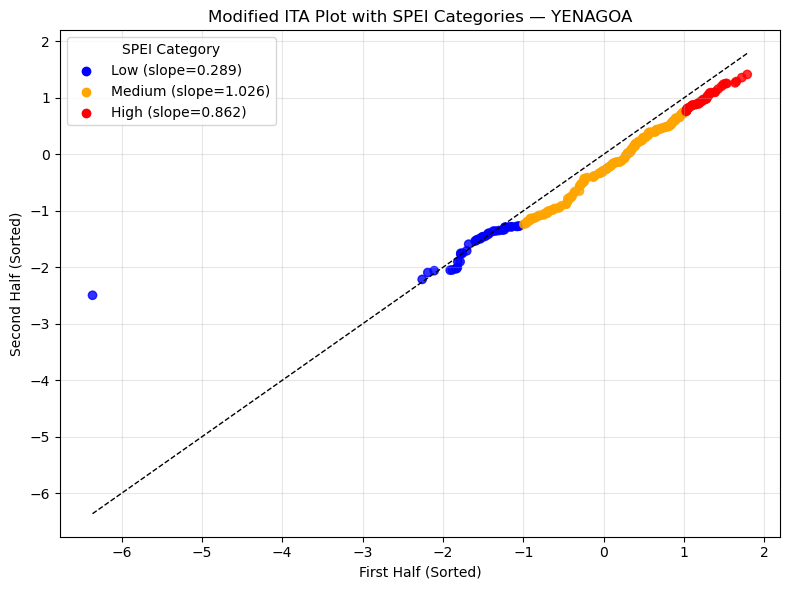

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# --------------------------------------
# Load data
# --------------------------------------
df = pd.read_excel("reshaped_climate_data.xlsx", sheet_name="SPEI_3")
df["Date"] = pd.to_datetime(df["Date"])
df.set_index("Date", inplace=True)

location = "YENAGOA"   # change for other stations
series = df[location].dropna()

# --------------------------------------
# Assign SPEI categories BEFORE splitting
# --------------------------------------
def categorize(v):
    if v <= -1:
        return "Low"
    elif v >= 1:
        return "High"
    else:
        return "Medium"

categories = series.apply(categorize)

# --------------------------------------
# Split into two halves
# --------------------------------------
n = len(series)
mid = n // 2

x_vals = series.iloc[:mid].copy()
y_vals = series.iloc[mid:mid+mid].copy()

x_cat = categories.iloc[:mid].copy()
y_cat = categories.iloc[mid:mid+mid].copy()

# --------------------------------------
# Sort both halves independently
# Maintain category labels!
# --------------------------------------
x_sorted_idx = np.argsort(x_vals)
y_sorted_idx = np.argsort(y_vals)

x_sorted = x_vals.iloc[x_sorted_idx].values
y_sorted = y_vals.iloc[y_sorted_idx].values

x_cat_sorted = x_cat.iloc[x_sorted_idx].values

# --------------------------------------
# Category colours for plotting
# --------------------------------------
colors = {"Low": "blue", "Medium": "orange", "High": "red"}
point_colors = [colors[c] for c in x_cat_sorted]

# -------------------------------------------------
# COMPUTE SLOPE FOR EACH CATEGORY GROUP
# -------------------------------------------------
slopes = {}

for cat in ["Low", "Medium", "High"]:
    mask = (x_cat_sorted == cat)
    
    if mask.sum() > 1:
        X = x_sorted[mask].reshape(-1,1)
        Y = y_sorted[mask]
        model = LinearRegression().fit(X, Y)
        slopes[cat] = model.coef_[0]
    else:
        slopes[cat] = np.nan

# -------------------------------------------------
# COMPUTE CLASSICAL IISC
# -------------------------------------------------
IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

# -------------------------------------------------
# COMPUTE IISC-C (Category-Based Sensitivity)
# -------------------------------------------------
slope_low = slopes["Low"]
slope_high = slopes["High"]

if not np.isnan(slope_low) and not np.isnan(slope_high) and (abs(slope_high + slope_low) > 0):
    IISC_C = (slope_high - slope_low) / abs(slope_high + slope_low)
else:
    IISC_C = np.nan

# -------------------------------------------------
# PRINT RESULTS
# -------------------------------------------------
print("\n=== CATEGORY SLOPES ===")
for c, s in slopes.items():
    print(f"{c} Group Slope: {s}")

print(f"\nClassical IISC: {IISC}")
print(f"IISC-C (Category-Based Sensitivity): {IISC_C}")

# --------------------------------------
# PLOT ITA WITH CATEGORY OVERLAY
# --------------------------------------
plt.figure(figsize=(8,6))

plt.scatter(x_sorted, y_sorted, c=point_colors, alpha=0.8)

# 1:1 reference line
maxv = max(max(x_sorted), max(y_sorted))
minv = min(min(x_sorted), min(y_sorted))
plt.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

plt.title(f"Modified ITA Plot with SPEI Categories — {location}")
plt.xlabel("First Half (Sorted)")
plt.ylabel("Second Half (Sorted)")

# Legend showing slopes
for lab, col in colors.items():
    slope_value = slopes[lab]
    label_text = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (slope=N/A)"
    plt.scatter([], [], color=col, label=label_text)

plt.legend(title="SPEI Category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

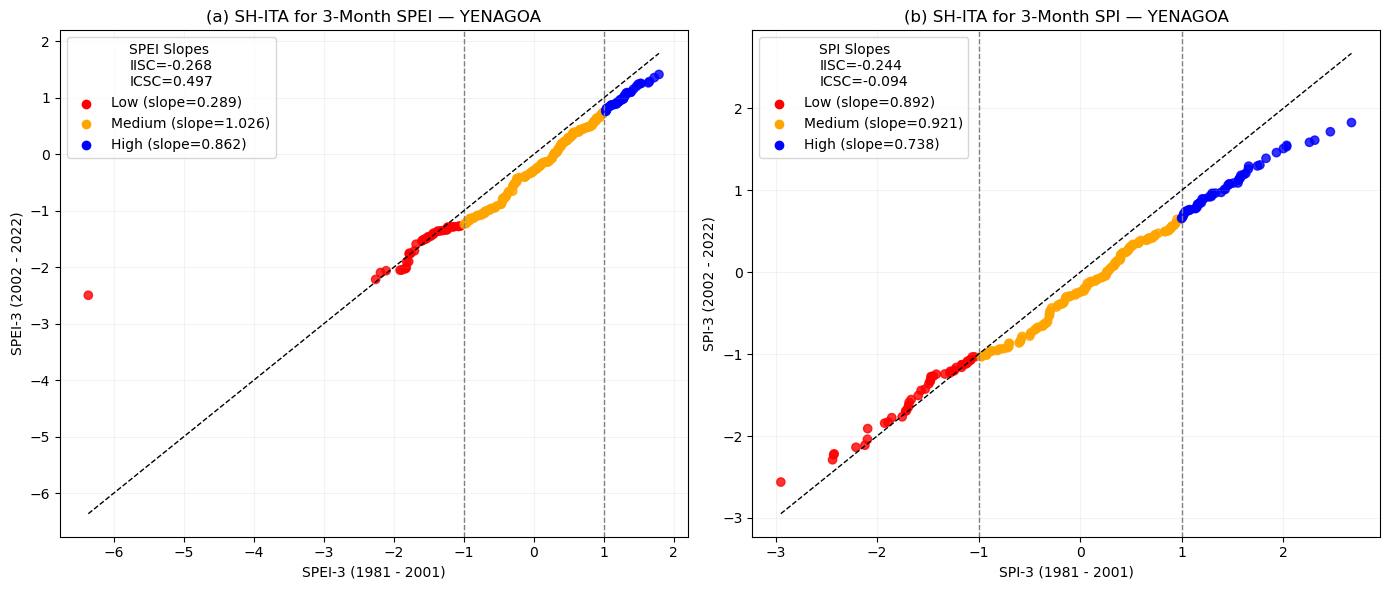


      YENAGOA RESULTS

--- SPEI-3 ---
Slopes: {'Low': 0.28938916563438594, 'Medium': 1.0257450346081678, 'High': 0.8619666883761886}
IISC: -0.26765717248267856
ICSC: 0.49730717114723055

--- SPI-3 ---
Slopes: {'Low': 0.8922807334241234, 'Medium': 0.9209917058438816, 'High': 0.7384710768239763}
IISC: -0.24374871403599602
ICSC: -0.09431824979961038


In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_3"
sheet_SPI  = "SPI_3"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "YENAGOA"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 3-Month SPEI — {location}")
ax.set_xlabel("SPEI-3 (1981 - 2001)")
ax.set_ylabel("SPEI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 3-Month SPI — {location}")
ax.set_xlabel("SPI-3 (1981 - 2001)")
ax.set_ylabel("SPI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-3 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-3 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


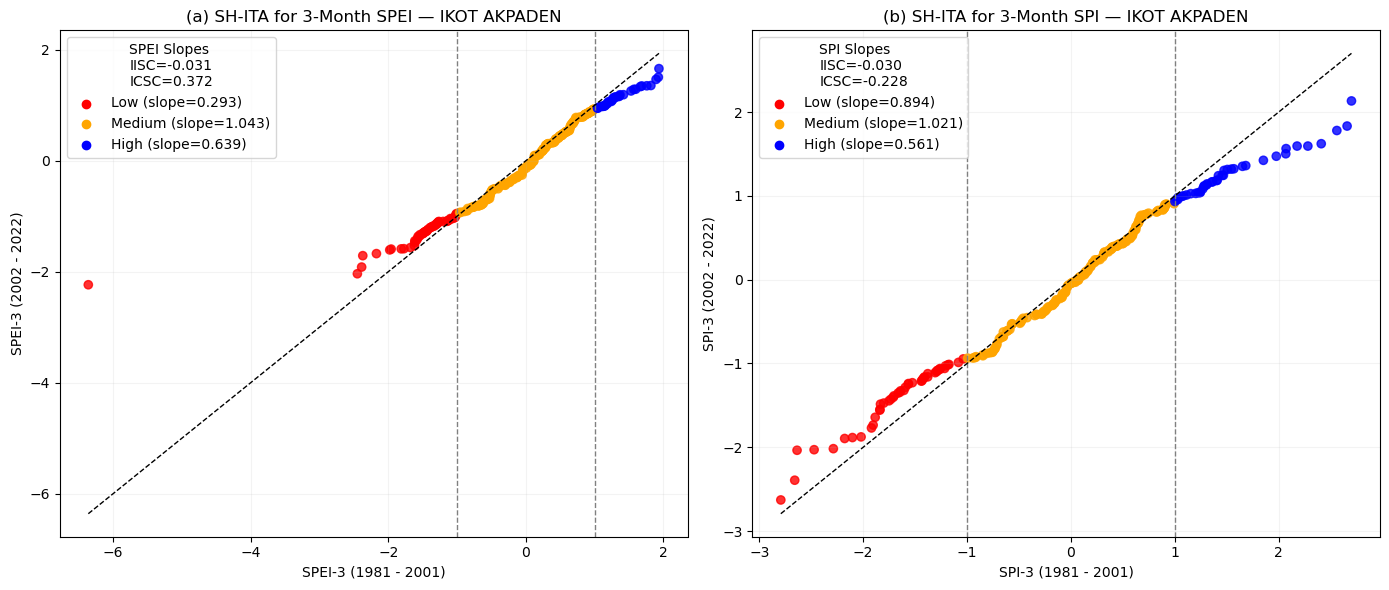


      IKOT AKPADEN RESULTS

--- SPEI-3 ---
Slopes: {'Low': 0.2926829122284175, 'Medium': 1.0425786709586622, 'High': 0.6387176366418537}
IISC: -0.03127880397262599
ICSC: 0.3715208508661004

--- SPI-3 ---
Slopes: {'Low': 0.8940489035033188, 'Medium': 1.0209094192110417, 'High': 0.5614959893891335}
IISC: -0.030451776934967346
ICSC: -0.22847314139060163


In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_3"
sheet_SPI  = "SPI_3"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "IKOT AKPADEN"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 3-Month SPEI — {location}")
ax.set_xlabel("SPEI-3 (1981 - 2001)")
ax.set_ylabel("SPEI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 3-Month SPI — {location}")
ax.set_xlabel("SPI-3 (1981 - 2001)")
ax.set_ylabel("SPI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-3 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-3 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


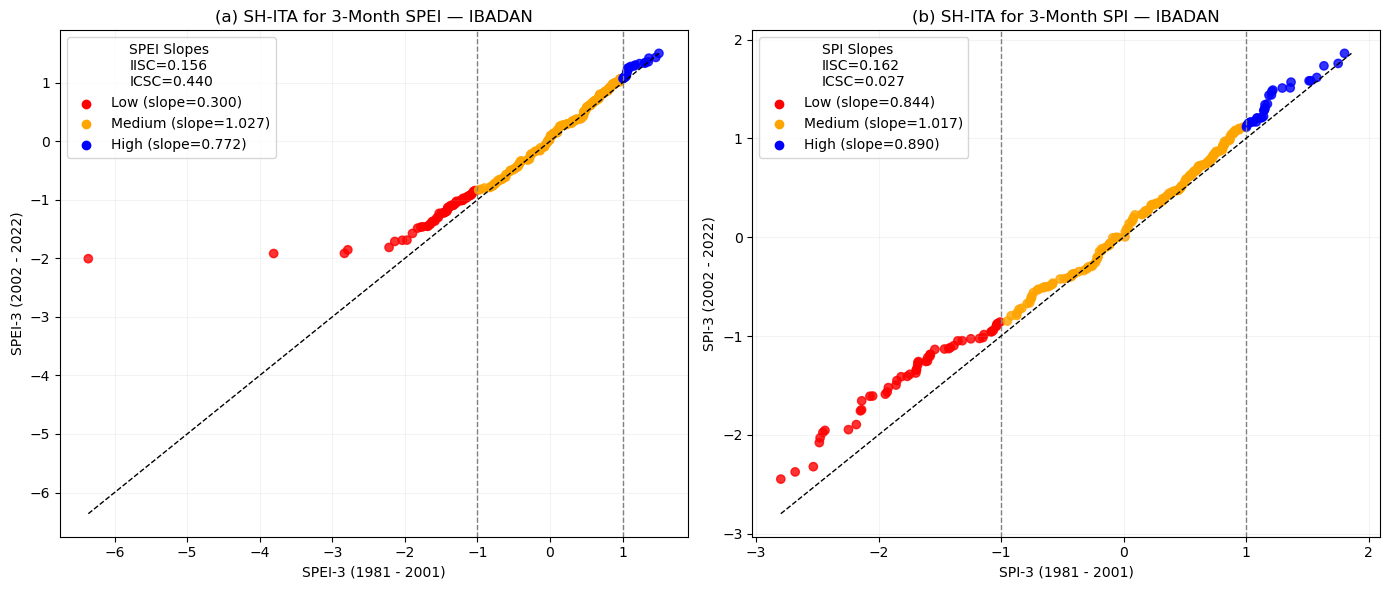


      IBADAN RESULTS

--- SPEI-3 ---
Slopes: {'Low': 0.3003609282353043, 'Medium': 1.0271708162552133, 'High': 0.7724937821766918}
IISC: 0.15632107940059653
ICSC: 0.4400715673421239

--- SPI-3 ---
Slopes: {'Low': 0.8438393183586794, 'Medium': 1.0167000995104014, 'High': 0.890328363342079}
IISC: 0.16180232380447712
ICSC: 0.026807698859781626


In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_3"
sheet_SPI  = "SPI_3"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "IBADAN"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 3-Month SPEI — {location}")
ax.set_xlabel("SPEI-3 (1981 - 2001)")
ax.set_ylabel("SPEI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 3-Month SPI — {location}")
ax.set_xlabel("SPI-3 (1981 - 2001)")
ax.set_ylabel("SPI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-3 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-3 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


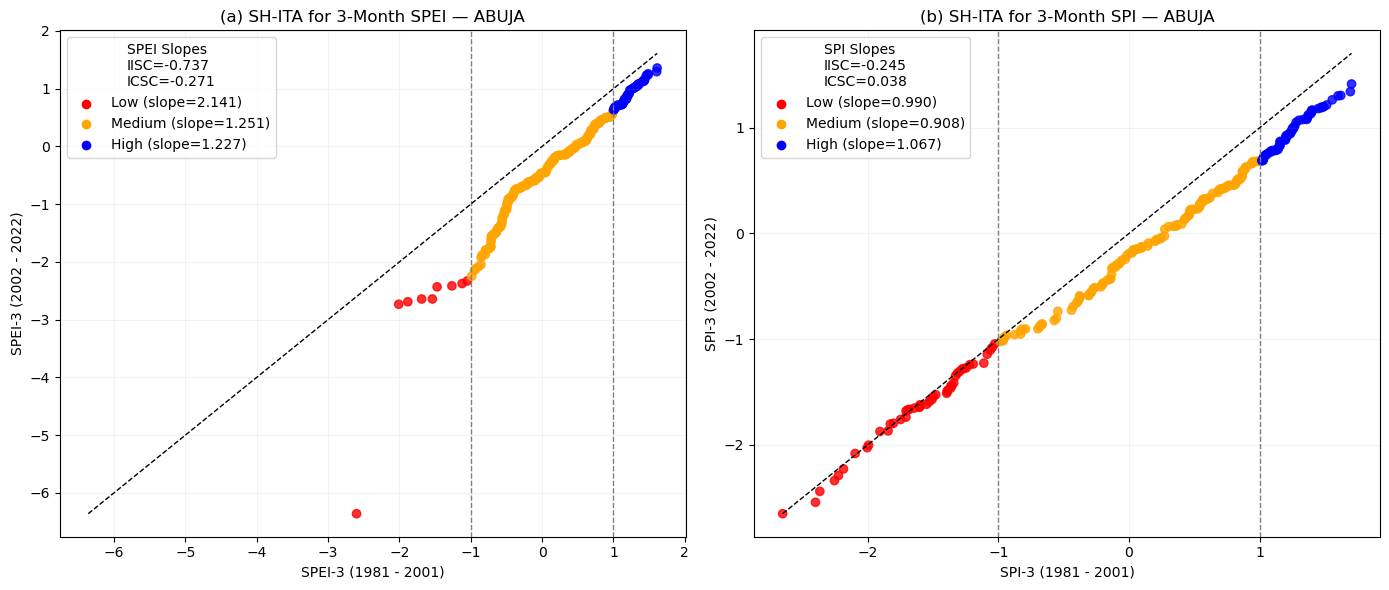


      ABUJA RESULTS

--- SPEI-3 ---
Slopes: {'Low': 2.1407338534383054, 'Medium': 1.251369512134026, 'High': 1.2270670120609903}
IISC: -0.7371895216756532
ICSC: -0.2712947938036291

--- SPI-3 ---
Slopes: {'Low': 0.9896684189903475, 'Medium': 0.9083681237719752, 'High': 1.0673013623543135}
IISC: -0.245385903074901
ICSC: 0.03774141169600293


In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_3"
sheet_SPI  = "SPI_3"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "ABUJA"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 3-Month SPEI — {location}")
ax.set_xlabel("SPEI-3 (1981 - 2001)")
ax.set_ylabel("SPEI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 3-Month SPI — {location}")
ax.set_xlabel("SPI-3 (1981 - 2001)")
ax.set_ylabel("SPI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-3 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-3 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


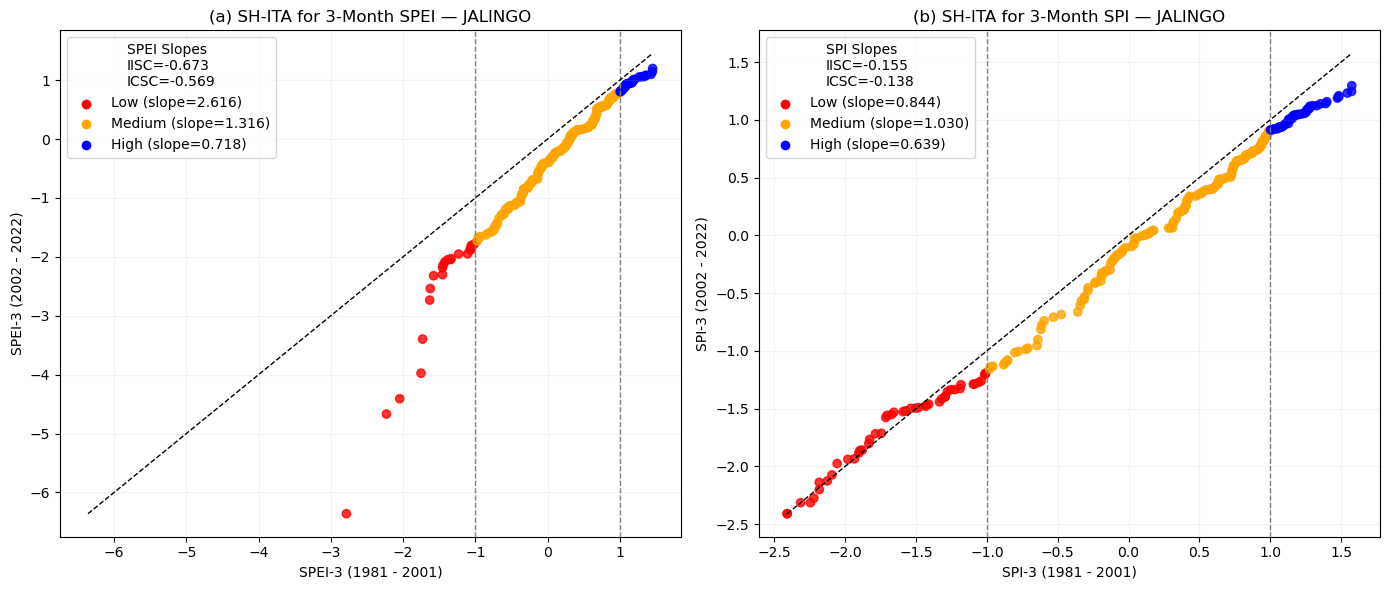


      JALINGO RESULTS

--- SPEI-3 ---
Slopes: {'Low': 2.615923041084771, 'Medium': 1.3164105765605847, 'High': 0.7184936584479632}
IISC: -0.6725947160177542
ICSC: -0.5690438699226472

--- SPI-3 ---
Slopes: {'Low': 0.8443638760717459, 'Medium': 1.0298308170763442, 'High': 0.6389890235483489}
IISC: -0.154943653106392
ICSC: -0.13845313045600685


In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_3"
sheet_SPI  = "SPI_3"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "JALINGO"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 3-Month SPEI — {location}")
ax.set_xlabel("SPEI-3 (1981 - 2001)")
ax.set_ylabel("SPEI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 3-Month SPI — {location}")
ax.set_xlabel("SPI-3 (1981 - 2001)")
ax.set_ylabel("SPI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-3 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-3 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


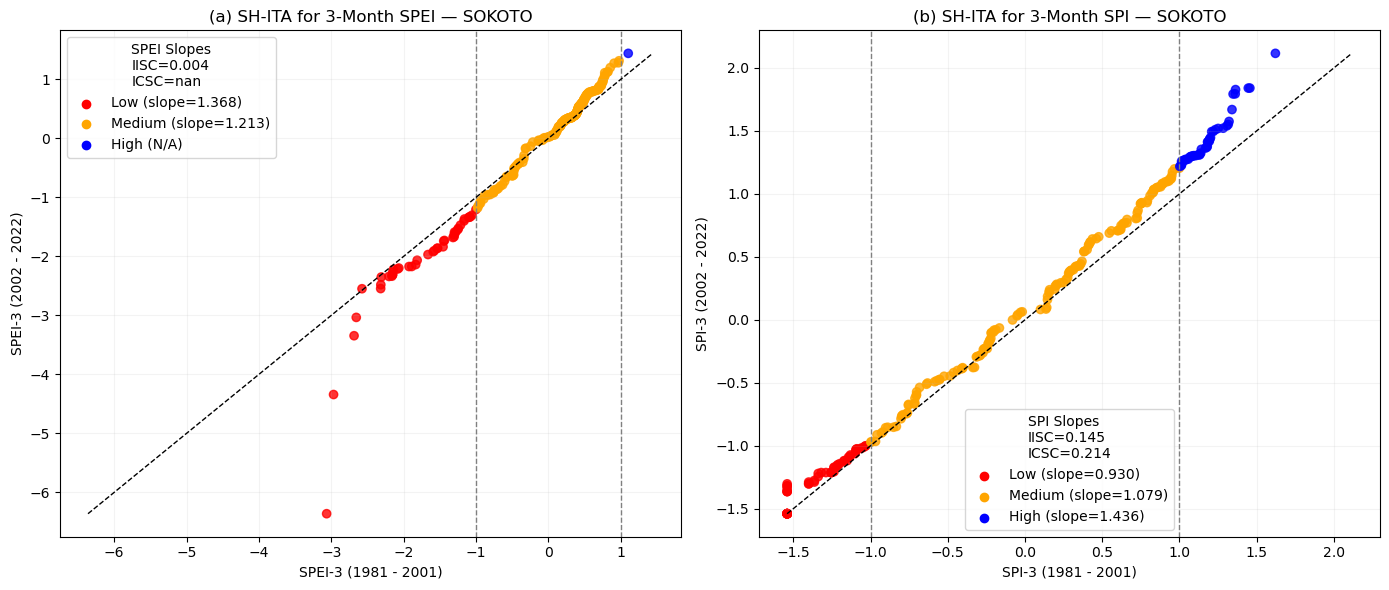


      SOKOTO RESULTS

--- SPEI-3 ---
Slopes: {'Low': 1.3679669767733527, 'Medium': 1.2132410416948145, 'High': nan}
IISC: 0.00357421077295747
ICSC: nan

--- SPI-3 ---
Slopes: {'Low': 0.9297258493446553, 'Medium': 1.079225320228081, 'High': 1.4362176578105226}
IISC: 0.14484996824723542
ICSC: 0.21407603644555126


In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_3"
sheet_SPI  = "SPI_3"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "SOKOTO"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 3-Month SPEI — {location}")
ax.set_xlabel("SPEI-3 (1981 - 2001)")
ax.set_ylabel("SPEI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 3-Month SPI — {location}")
ax.set_xlabel("SPI-3 (1981 - 2001)")
ax.set_ylabel("SPI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-3 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-3 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


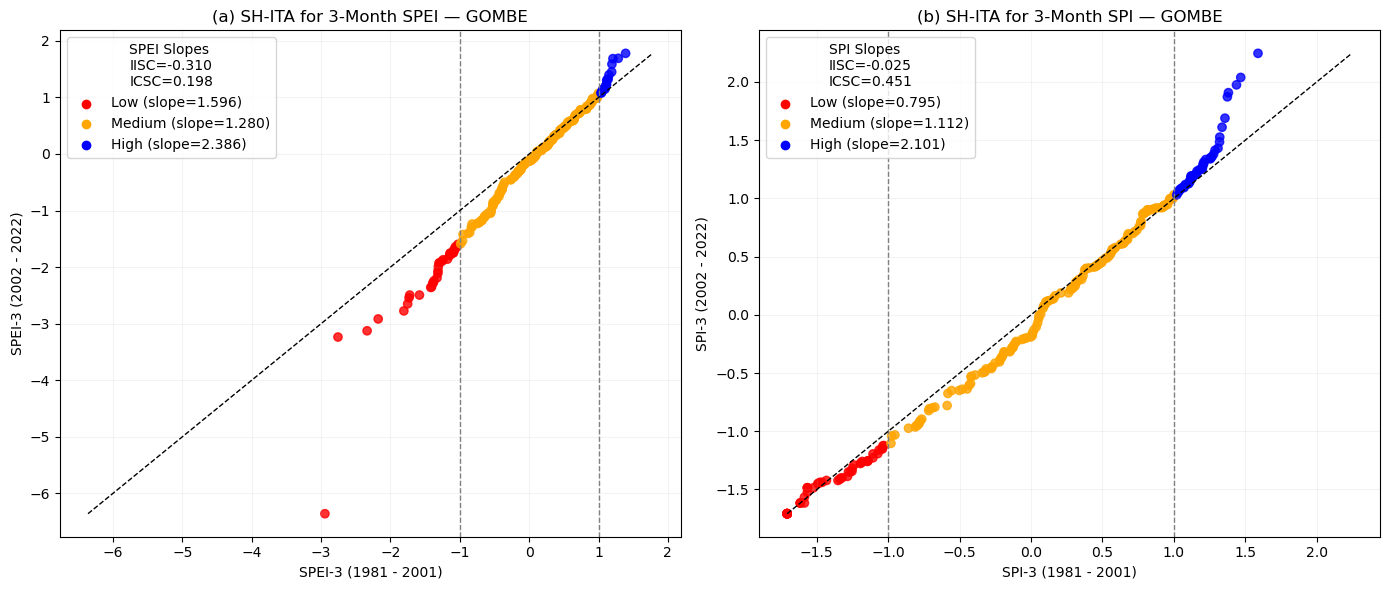


      GOMBE RESULTS

--- SPEI-3 ---
Slopes: {'Low': 1.5963348423577584, 'Medium': 1.279748690006623, 'High': 2.3856111788044965}
IISC: -0.31026253686556177
ICSC: 0.19821372069136267

--- SPI-3 ---
Slopes: {'Low': 0.7954487711199042, 'Medium': 1.1123284808822025, 'High': 2.1006142580392213}
IISC: -0.024936790448145493
ICSC: 0.45066888178130327


In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_3"
sheet_SPI  = "SPI_3"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "GOMBE"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 3-Month SPEI — {location}")
ax.set_xlabel("SPEI-3 (1981 - 2001)")
ax.set_ylabel("SPEI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 3-Month SPI — {location}")
ax.set_xlabel("SPI-3 (1981 - 2001)")
ax.set_ylabel("SPI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-3 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-3 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


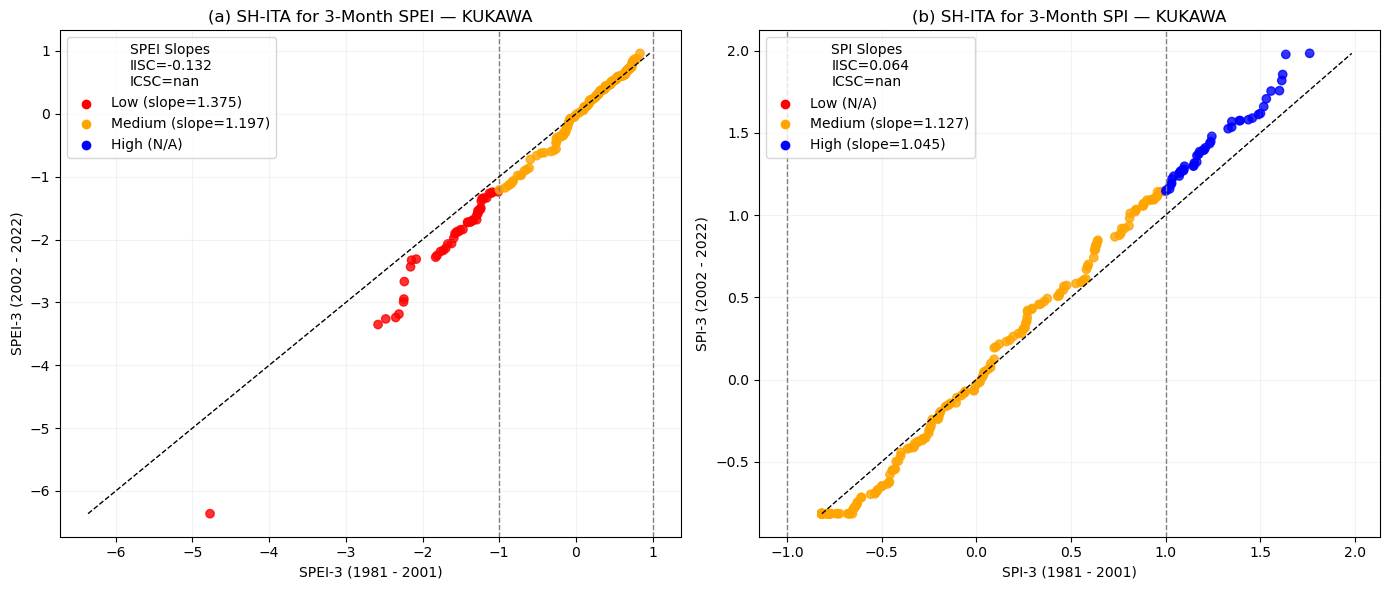


      KUKAWA RESULTS

--- SPEI-3 ---
Slopes: {'Low': 1.3753263588779454, 'Medium': 1.1966149733980052, 'High': nan}
IISC: -0.13185196217003364
ICSC: nan

--- SPI-3 ---
Slopes: {'Low': nan, 'Medium': 1.1274098834880926, 'High': 1.0448174139215327}
IISC: 0.06412837592728535
ICSC: nan


In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_3"
sheet_SPI  = "SPI_3"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "KUKAWA"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 3-Month SPEI — {location}")
ax.set_xlabel("SPEI-3 (1981 - 2001)")
ax.set_ylabel("SPEI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 3-Month SPI — {location}")
ax.set_xlabel("SPI-3 (1981 - 2001)")
ax.set_ylabel("SPI-3 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-3 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-3 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


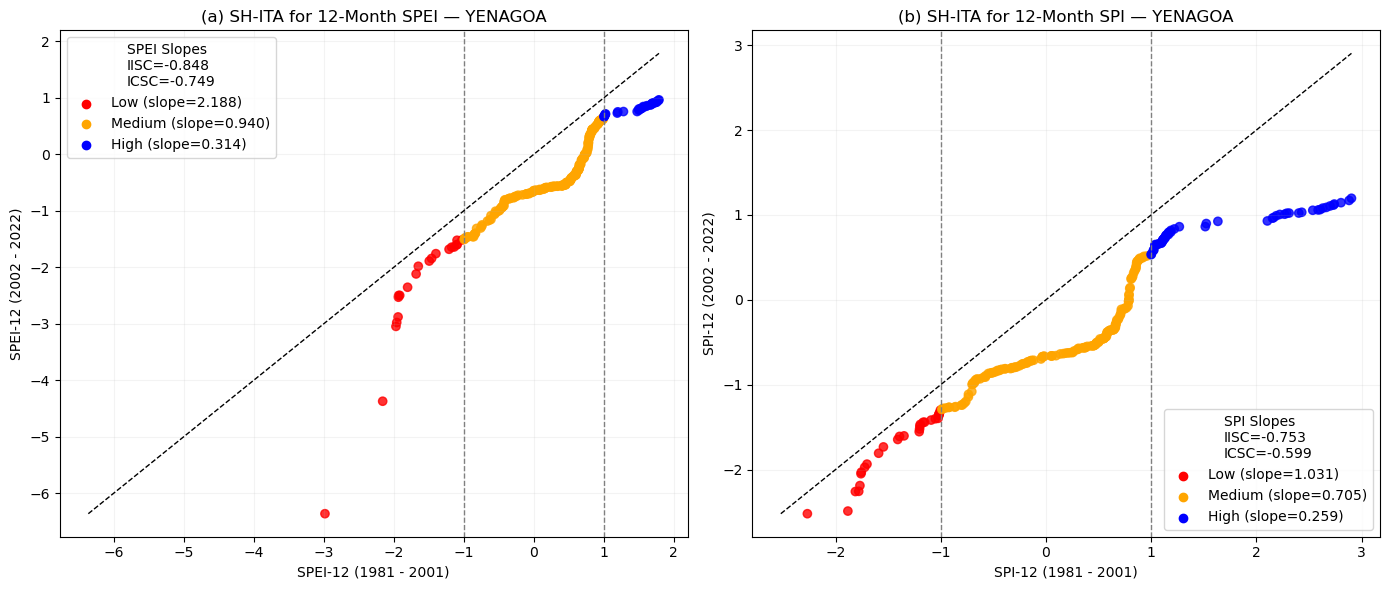


      YENAGOA RESULTS

--- SPEI-12 ---
Slopes: {'Low': 2.187887106235897, 'Medium': 0.9395866784115976, 'High': 0.31405760223172596}
IISC: -0.8476702786501998
ICSC: -0.7489492064562225

--- SPI-12 ---
Slopes: {'Low': 1.0312617235555117, 'Medium': 0.7052485075517599, 'High': 0.2586193346671956}
IISC: -0.7531847357363085
ICSC: -0.5990028180993054


In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_12"
sheet_SPI  = "SPI_12"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "YENAGOA"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 12-Month SPEI — {location}")
ax.set_xlabel("SPEI-12 (1981 - 2001)")
ax.set_ylabel("SPEI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 12-Month SPI — {location}")
ax.set_xlabel("SPI-12 (1981 - 2001)")
ax.set_ylabel("SPI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-12 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-12 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


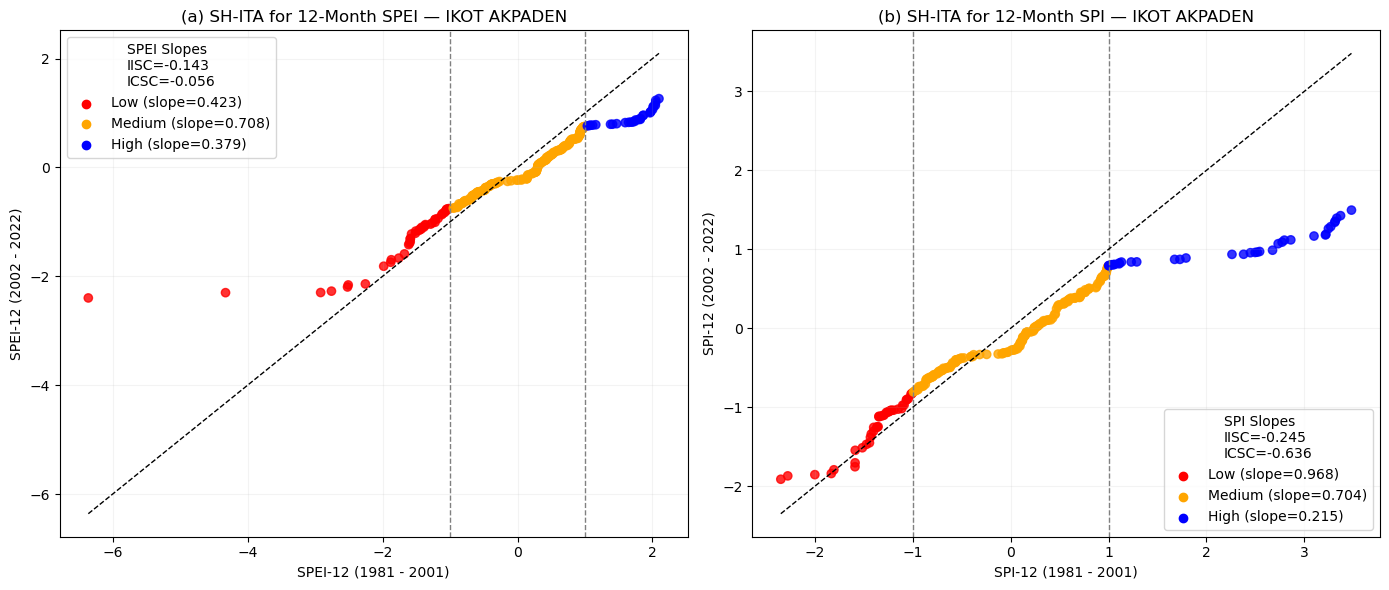


      IKOT AKPADEN RESULTS

--- SPEI-12 ---
Slopes: {'Low': 0.42326924233702296, 'Medium': 0.7075484298483803, 'High': 0.37867933905712536}
IISC: -0.14341121088968714
ICSC: -0.055601947948308895

--- SPI-12 ---
Slopes: {'Low': 0.9677790626599196, 'Medium': 0.7035451991661346, 'High': 0.2152612415838188}
IISC: -0.24527665799418197
ICSC: -0.6360880676479993


In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_12"
sheet_SPI  = "SPI_12"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "IKOT AKPADEN"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 12-Month SPEI — {location}")
ax.set_xlabel("SPEI-12 (1981 - 2001)")
ax.set_ylabel("SPEI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 12-Month SPI — {location}")
ax.set_xlabel("SPI-12 (1981 - 2001)")
ax.set_ylabel("SPI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-12 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-12 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


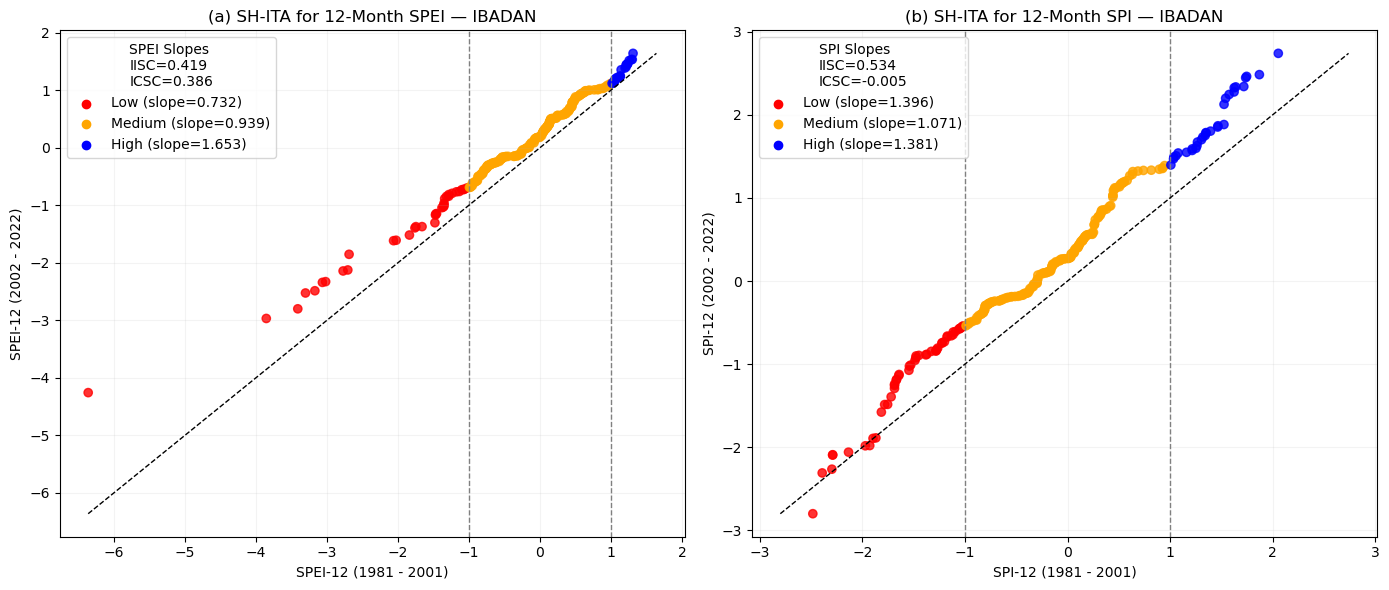


      IBADAN RESULTS

--- SPEI-12 ---
Slopes: {'Low': 0.7318529719764021, 'Medium': 0.9386328762781978, 'High': 1.6526523943556388}
IISC: 0.4191043732077267
ICSC: 0.38615950938103943

--- SPI-12 ---
Slopes: {'Low': 1.3958689415324497, 'Medium': 1.0705249138140924, 'High': 1.3809813910921347}
IISC: 0.533720941225761
ICSC: -0.00536130819346096


In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_12"
sheet_SPI  = "SPI_12"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "IBADAN"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 12-Month SPEI — {location}")
ax.set_xlabel("SPEI-12 (1981 - 2001)")
ax.set_ylabel("SPEI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 12-Month SPI — {location}")
ax.set_xlabel("SPI-12 (1981 - 2001)")
ax.set_ylabel("SPI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-12 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-12 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


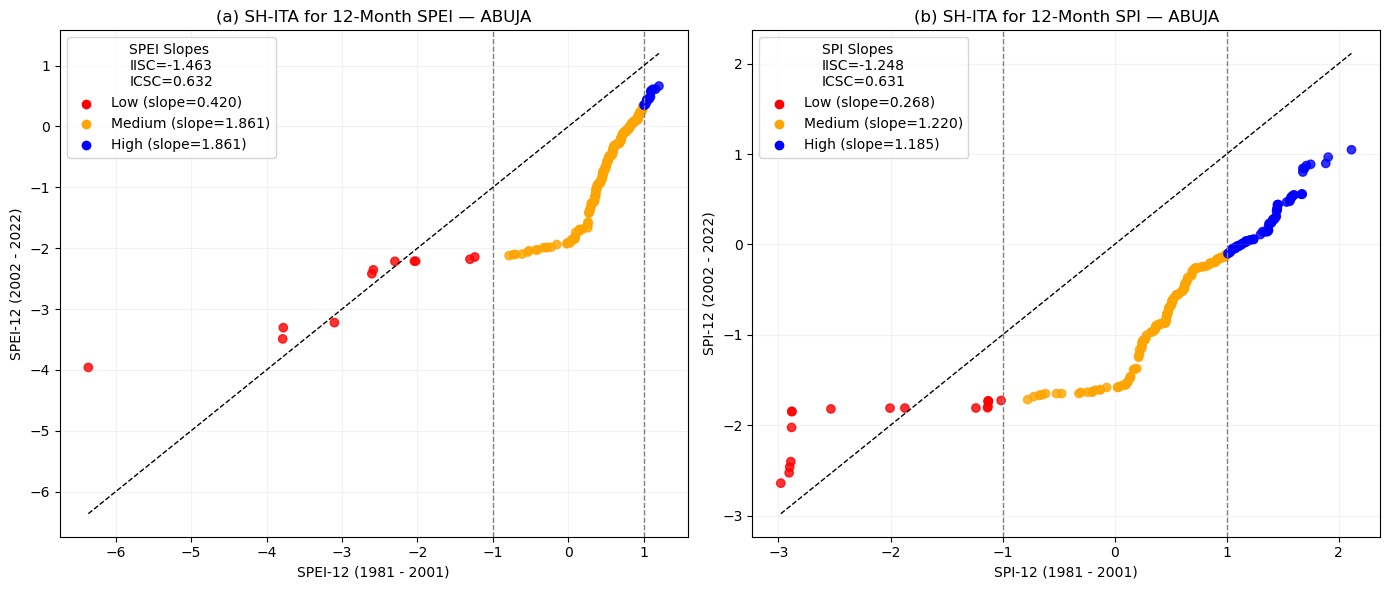


      ABUJA RESULTS

--- SPEI-12 ---
Slopes: {'Low': 0.42010419401122084, 'Medium': 1.8614929462228234, 'High': 1.8606953477373274}
IISC: -1.4633898025608487
ICSC: 0.6316167323594314

--- SPI-12 ---
Slopes: {'Low': 0.26787491373676775, 'Medium': 1.2202733826629812, 'High': 1.1847420721728439}
IISC: -1.247885841086132
ICSC: 0.6311830078607712


In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_12"
sheet_SPI  = "SPI_12"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "ABUJA"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 12-Month SPEI — {location}")
ax.set_xlabel("SPEI-12 (1981 - 2001)")
ax.set_ylabel("SPEI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 12-Month SPI — {location}")
ax.set_xlabel("SPI-12 (1981 - 2001)")
ax.set_ylabel("SPI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-12 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-12 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


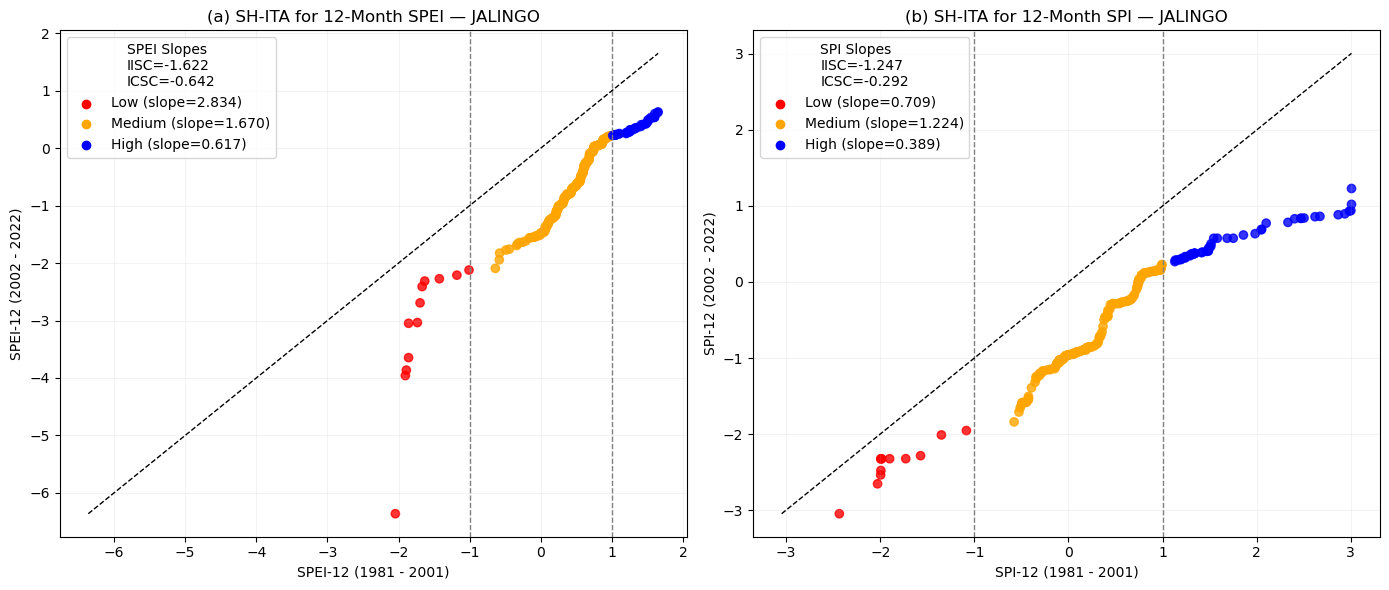


      JALINGO RESULTS

--- SPEI-12 ---
Slopes: {'Low': 2.8342540720226945, 'Medium': 1.6703417497819024, 'High': 0.6172056121826932}
IISC: -1.6219326575494568
ICSC: -0.6423509652990257

--- SPI-12 ---
Slopes: {'Low': 0.7091158028564204, 'Medium': 1.2235416254163336, 'High': 0.3885688640875467}
IISC: -1.2468045555029819
ICSC: -0.2920209677896835


In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_12"
sheet_SPI  = "SPI_12"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "JALINGO"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 12-Month SPEI — {location}")
ax.set_xlabel("SPEI-12 (1981 - 2001)")
ax.set_ylabel("SPEI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 12-Month SPI — {location}")
ax.set_xlabel("SPI-12 (1981 - 2001)")
ax.set_ylabel("SPI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-12 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-12 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


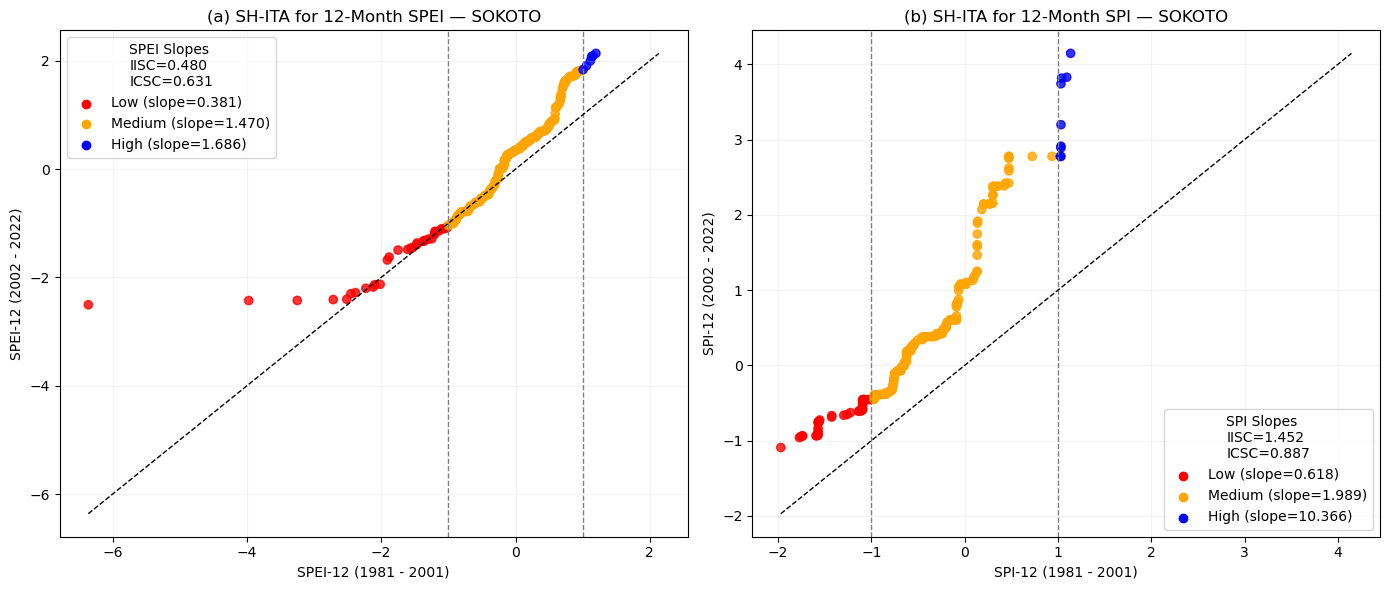


      SOKOTO RESULTS

--- SPEI-12 ---
Slopes: {'Low': 0.3810257182442366, 'Medium': 1.4699906220661152, 'High': 1.6864566966711232}
IISC: 0.47975933240847135
ICSC: 0.6314109222933

--- SPI-12 ---
Slopes: {'Low': 0.6181836383331806, 'Medium': 1.9886157828374285, 'High': 10.366001883391283}
IISC: 1.4518130960174886
ICSC: 0.8874411512605027


In [118]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_12"
sheet_SPI  = "SPI_12"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "SOKOTO"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 12-Month SPEI — {location}")
ax.set_xlabel("SPEI-12 (1981 - 2001)")
ax.set_ylabel("SPEI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 12-Month SPI — {location}")
ax.set_xlabel("SPI-12 (1981 - 2001)")
ax.set_ylabel("SPI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-12 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-12 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


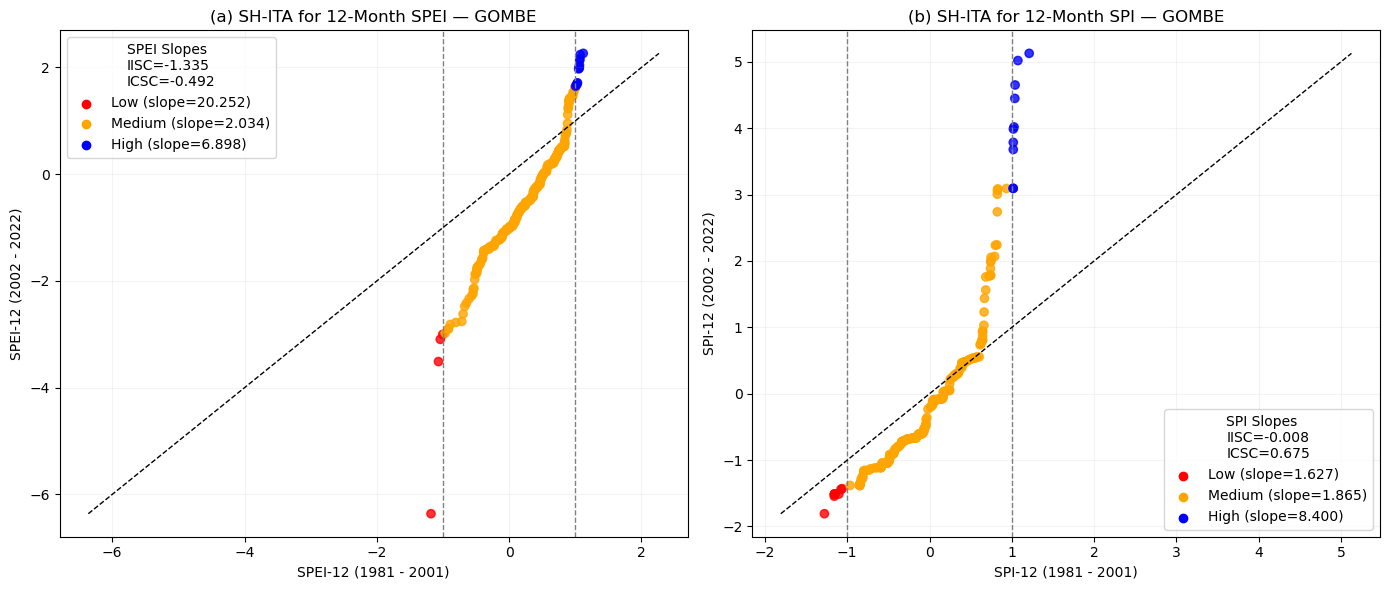


      GOMBE RESULTS

--- SPEI-12 ---
Slopes: {'Low': 20.251647703858108, 'Medium': 2.033542081968275, 'High': 6.897752503155692}
IISC: -1.3348285745628057
ICSC: -0.4918670430609572

--- SPI-12 ---
Slopes: {'Low': 1.6271248838677976, 'Medium': 1.864784350826007, 'High': 8.399774863604469}
IISC: -0.008430452568491604
ICSC: 0.6754480597498768


In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_12"
sheet_SPI  = "SPI_12"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "GOMBE"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 12-Month SPEI — {location}")
ax.set_xlabel("SPEI-12 (1981 - 2001)")
ax.set_ylabel("SPEI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 12-Month SPI — {location}")
ax.set_xlabel("SPI-12 (1981 - 2001)")
ax.set_ylabel("SPI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-12 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-12 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)


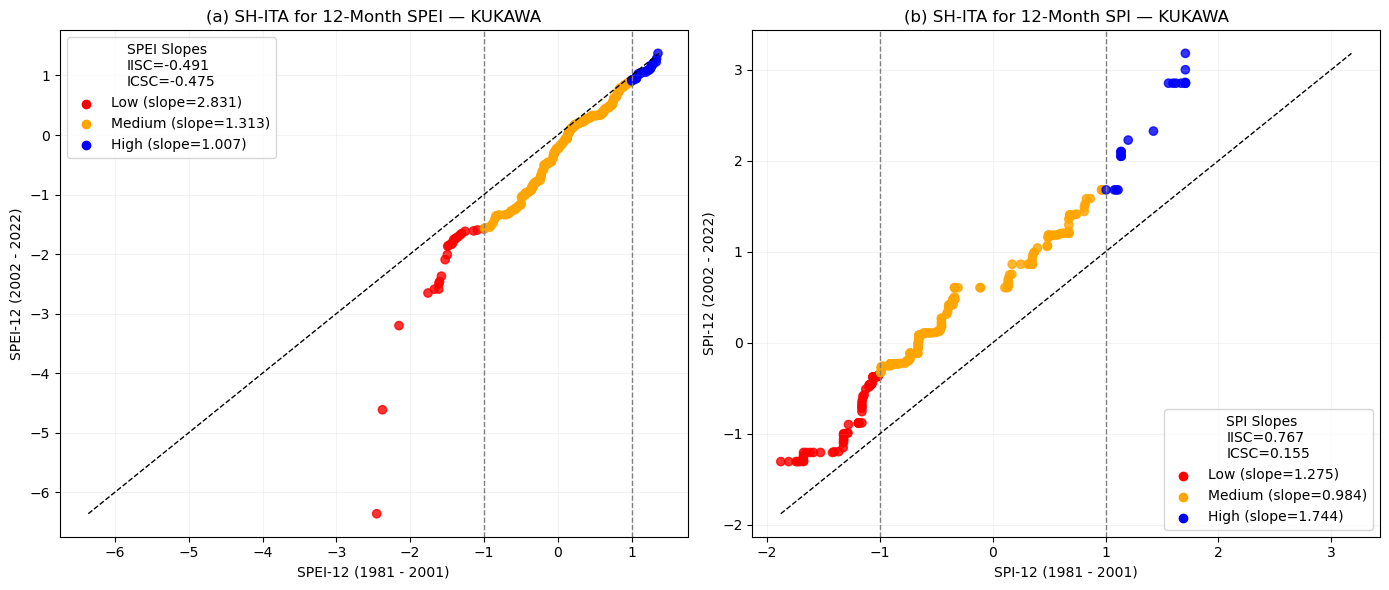


      KUKAWA RESULTS

--- SPEI-12 ---
Slopes: {'Low': 2.8307439300385875, 'Medium': 1.3132955993281343, 'High': 1.006717027738042}
IISC: -0.49136379091101307
ICSC: -0.4753212924822461

--- SPI-12 ---
Slopes: {'Low': 1.2753373052186145, 'Medium': 0.9836627773130926, 'High': 1.7435498446879754}
IISC: 0.7670190976760658
ICSC: 0.15509441599492987


In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# =====================================================
# FUNCTION TO COMPUTE ITA, SLOPES, IISC, IISC-C
# =====================================================
def run_ita(series):
    # Categorize
    def categorize(v):
        if v <= -1:
            return "Low"
        elif v >= 1:
            return "High"
        else:
            return "Medium"

    categories = series.apply(categorize)

    # Split into halves
    n = len(series)
    mid = n // 2

    x_vals = series.iloc[:mid].copy()
    y_vals = series.iloc[mid:mid+mid].copy()

    x_cat = categories.iloc[:mid].copy()

    # Sort both halves
    x_sorted_idx = np.argsort(x_vals)
    y_sorted_idx = np.argsort(y_vals)

    x_sorted = x_vals.iloc[x_sorted_idx].values
    y_sorted = y_vals.iloc[y_sorted_idx].values

    x_cat_sorted = x_cat.iloc[x_sorted_idx].values

    # Compute category slopes
    slopes = {}
    for cat in ["Low", "Medium", "High"]:
        mask = (x_cat_sorted == cat)
        if mask.sum() > 1:
            X = x_sorted[mask].reshape(-1, 1)
            Y = y_sorted[mask]
            model = LinearRegression().fit(X, Y)
            slopes[cat] = model.coef_[0]
        else:
            slopes[cat] = np.nan

    # Classical IISC
    classical_IISC = (np.mean(y_sorted) - np.mean(x_sorted)) / np.mean(np.abs(x_sorted))

    # IISC-C or ICSC
    slope_low = slopes["Low"]
    slope_high = slopes["High"]

    if not np.isnan(slope_low) and not np.isnan(slope_high) and abs(slope_high + slope_low) > 0:
        ICSC = (slope_high - slope_low) / abs(slope_high + slope_low)
    else:
        ICSC = np.nan

    return x_sorted, y_sorted, x_cat_sorted, slopes, classical_IISC, ICSC


# =====================================================
# LOAD DATA
# =====================================================
file = "reshaped_climate_data.xlsx"
sheet_SPEI = "SPEI_12"
sheet_SPI  = "SPI_12"

df_spei = pd.read_excel(file, sheet_name=sheet_SPEI)
df_spi  = pd.read_excel(file, sheet_name=sheet_SPI)

df_spei["Date"] = pd.to_datetime(df_spei["Date"])
df_spi["Date"]  = pd.to_datetime(df_spi["Date"])

df_spei.set_index("Date", inplace=True)
df_spi.set_index("Date", inplace=True)

location = "KUKAWA"   # <---- change this for other stations

spei_series = df_spei[location].dropna()
spi_series  = df_spi[location].dropna()

# =====================================================
# RUN ITA FOR BOTH INDICES
# =====================================================
spei_results = run_ita(spei_series)
spi_results  = run_ita(spi_series)

(x_spei, y_spei, cat_spei, slopes_spei, IISC_spei, ICSC_spei) = spei_results
(x_spi,  y_spi,  cat_spi,  slopes_spi,  IISC_spi,  ICSC_spi)  = spi_results

colors = {"Low": "red", "Medium": "orange", "High": "blue"}

# =====================================================
# PLOT (1 ROW × 2 COLUMNS)
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------------------------
# SPEI PLOT
# --------------------------
ax = axes[0]
point_colors = [colors[c] for c in cat_spei]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spei, y_spei, c=point_colors, alpha=0.8)

minv = min(min(x_spei), min(y_spei))
maxv = max(max(x_spei), max(y_spei))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(a) SH-ITA for 12-Month SPEI — {location}")
ax.set_xlabel("SPEI-12 (1981 - 2001)")
ax.set_ylabel("SPEI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spei[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPEI Slopes\nIISC={IISC_spei:.3f}\nICSC={ICSC_spei:.3f}")
ax.grid(alpha=0.15)

# --------------------------
# SPI PLOT
# --------------------------
ax = axes[1]
point_colors = [colors[c] for c in cat_spi]

# Vertical reference lines at -1 and +1 (CATEGORY BOUNDARIES)
ax.axvline(x=-1, color="gray", linestyle="--", linewidth=1)
ax.axvline(x=1, color="gray", linestyle="--", linewidth=1)

ax.scatter(x_spi, y_spi, c=point_colors, alpha=0.8)

minv = min(min(x_spi), min(y_spi))
maxv = max(max(x_spi), max(y_spi))
ax.plot([minv, maxv], [minv, maxv], 'k--', linewidth=1)

ax.set_title(f"(b) SH-ITA for 12-Month SPI — {location}")
ax.set_xlabel("SPI-12 (1981 - 2001)")
ax.set_ylabel("SPI-12 (2002 - 2022)")

for lab, col in colors.items():
    slope_value = slopes_spi[lab]
    txt = f"{lab} (slope={slope_value:.3f})" if not np.isnan(slope_value) else f"{lab} (N/A)"
    ax.scatter([], [], color=col, label=txt)

ax.legend(title=f"SPI Slopes\nIISC={IISC_spi:.3f}\nICSC={ICSC_spi:.3f}")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# =====================================================
# PRINT VALUES FOR REPORTING
# =====================================================
print("\n========================")
print(f"      {location} RESULTS")
print("========================")

print("\n--- SPEI-12 ---")
print("Slopes:", slopes_spei)
print("IISC:", IISC_spei)
print("ICSC:", ICSC_spei)

print("\n--- SPI-12 ---")
print("Slopes:", slopes_spi)
print("IISC:", IISC_spi)
print("ICSC:", ICSC_spi)
